In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

In [14]:
import os

print(os.listdir('/kaggle/input/datasets/nishunegi21/churn-modelling'))

['Customer-Churn-Records.csv']


In [15]:
import glob

files = glob.glob('/kaggle/input/**/*.csv', recursive=True)
print(files)

['/kaggle/input/datasets/nishunegi21/churn-modelling/Customer-Churn-Records.csv']


In [16]:
import pandas as pd

df = pd.read_csv('/kaggle/input/datasets/nishunegi21/churn-modelling/Customer-Churn-Records.csv')

print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  Complain  Satisfaction Score Card Type  \
0        101348.88       1         1                   2   DIAMOND   
1        112542.58

In [17]:
df.head()
df.shape
df.columns
df.info()
df.describe()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

np.int64(0)

In [18]:
#data cleaning
df = df.drop_duplicates()
print(df.isnull().sum())

RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64


In [24]:
#numerical columns
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

#categorical columns
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0


In [29]:
df = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname'],
    errors='ignore'
)

#removing irrelevant fields like rownumber, customer id, surname, since they're not useful for the analysis

In [31]:
print(df.shape)
print(df.isnull().sum())
#cleaned data

(10000, 15)
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64


In [33]:
#calculating churn rate

total = len(df)
churned = df['Exited'].sum()
retained = total - churned
churn_rate = (churned / total) * 100
retention_rate = (retained / total) * 100

print("Total Customers:", total)
print("Churned Customers:", churned)
print("Retained Customers:", retained)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 10000
Churned Customers: 2038
Retained Customers: 7962
Churn Rate: 20.38 %
Retention Rate: 79.62 %


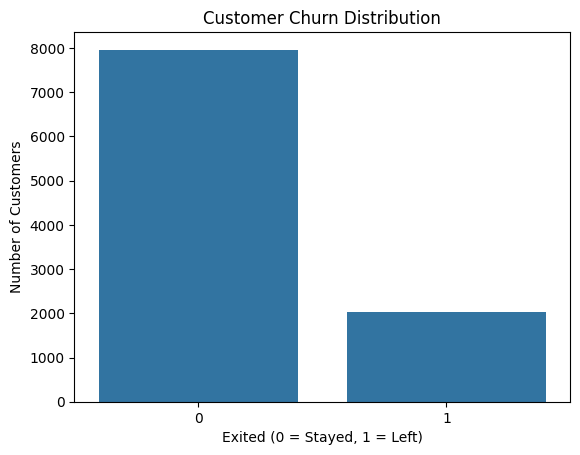

In [34]:
#how many customers left vs stayed?

sns.countplot(data=df, x='Exited')
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()

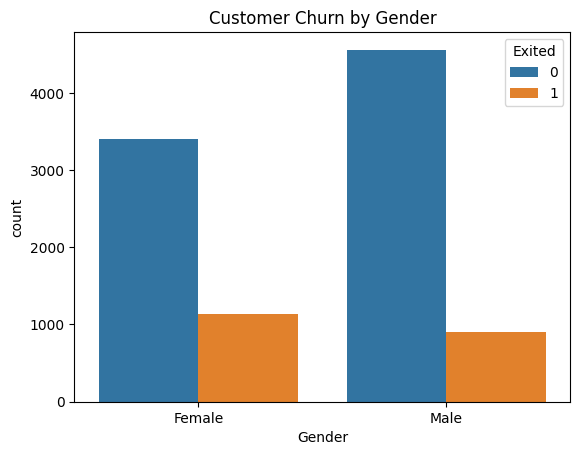

In [35]:
#churn based on gender (0=retained, 1=churned)
sns.countplot(
    data=df,
    x='Gender',
    hue='Exited'
)

plt.title("Customer Churn by Gender")
plt.show()

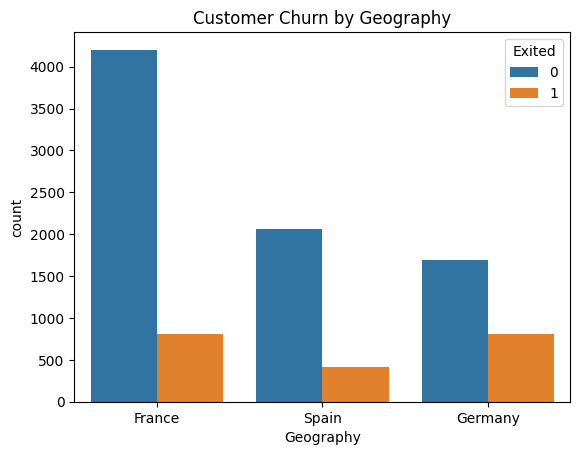

In [36]:
#churn based on geography
sns.countplot(
    data=df,
    x='Geography',
    hue='Exited'
)

plt.title("Customer Churn by Geography")
plt.show()

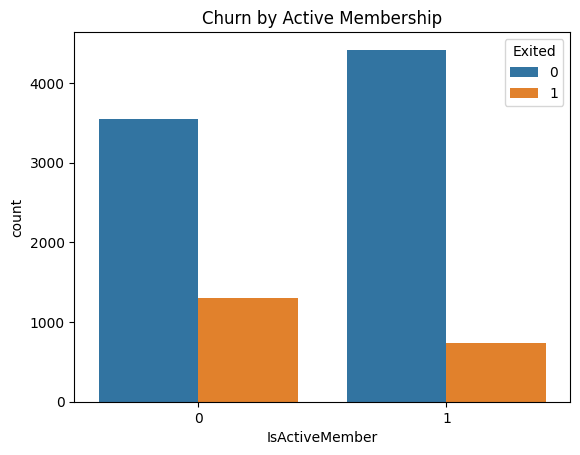

In [37]:
#churn based on active membership
sns.countplot(
    data=df,
    x='IsActiveMember',
    hue='Exited'
)

plt.title("Churn by Active Membership")
plt.show()

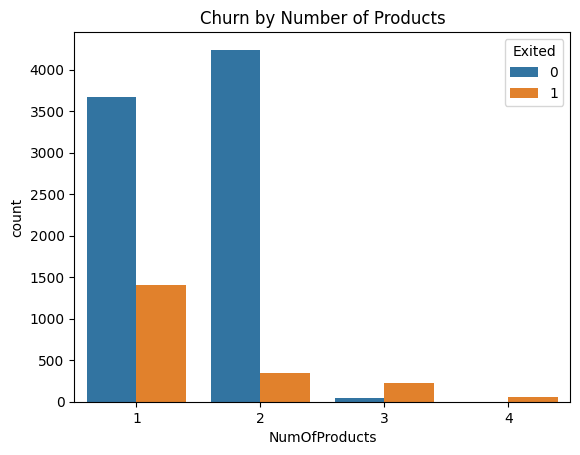

In [38]:
#churn based on number of products
sns.countplot(
    data=df,
    x='NumOfProducts',
    hue='Exited'
)

plt.title("Churn by Number of Products")
plt.show()

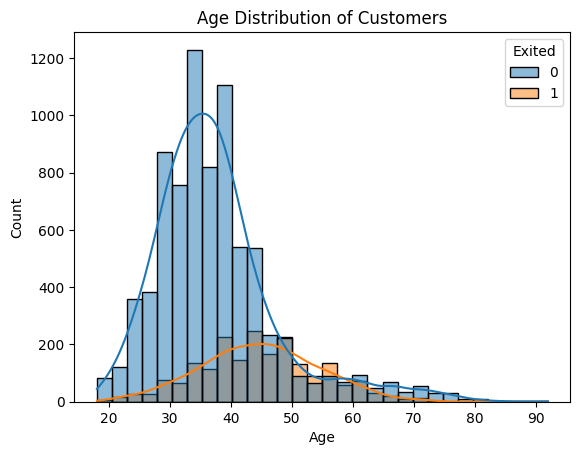

In [39]:
#customer age distribution
sns.histplot(
    data=df,
    x='Age',
    hue='Exited',
    bins=30,
    kde=True
)

plt.title("Age Distribution of Customers")
plt.show()

churn rates compared by percentages:

In [40]:
#churn by geography (% comparison)
geo_churn = df.groupby('Geography')['Exited'].mean() * 100

print(geo_churn)

Geography
France     16.174711
Germany    32.443204
Spain      16.673395
Name: Exited, dtype: float64


In [41]:
#by gender
gender_churn = df.groupby('Gender')['Exited'].mean() * 100

print(gender_churn)

Gender
Female    25.071539
Male      16.474253
Name: Exited, dtype: float64


In [42]:
#by active membership
active_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100

print(active_churn)

IsActiveMember
0    26.871520
1    14.269074
Name: Exited, dtype: float64


In [43]:
#by number of products
product_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100

print(product_churn)

NumOfProducts
1     27.714398
2      7.603486
3     82.706767
4    100.000000
Name: Exited, dtype: float64


In [46]:
#by age group
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['Below 25', '25-35', '35-45', '45-55', '55+']
)
age_churn = df.groupby(
    'AgeGroup',
    observed=False
)['Exited'].mean() * 100

print(age_churn)

AgeGroup
Below 25     7.528642
25-35        8.498024
35-45       19.646681
45-55       50.572082
55+         36.750000
Name: Exited, dtype: float64


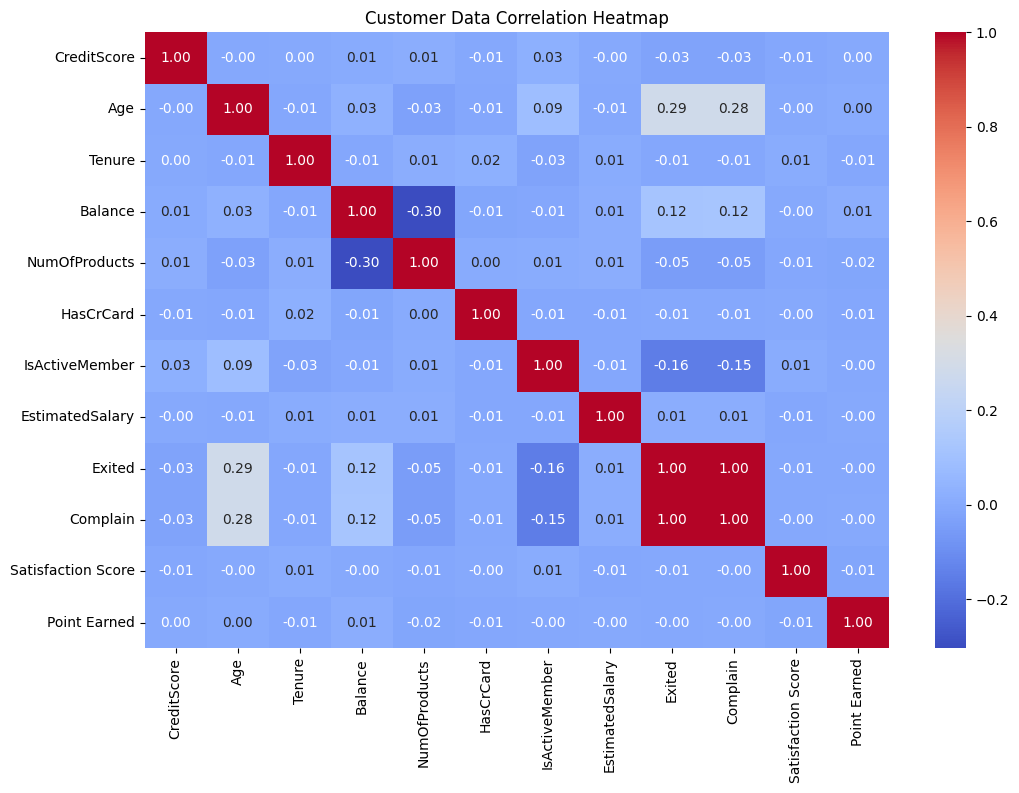

In [47]:
#correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Customer Data Correlation Heatmap")
plt.show()

In [48]:
#saving cleaned dataset
df.to_csv(
    '/kaggle/working/bank_churn_clean.csv',
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [49]:
os.listdir('/kaggle/working')

['bank_churn_clean.csv', '.virtual_documents']

**SQL:**

In [50]:
import sqlite3

conn = sqlite3.connect(
    '/kaggle/working/bank_churn.db'
)

df.to_sql(
    'bank_customers',
    conn,
    if_exists='replace',
    index=False
)

print("Database created successfully!")

Database created successfully!


In [51]:
query = """
SELECT *
FROM bank_customers
LIMIT 10;
"""

pd.read_sql_query(query, conn)

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned,AgeGroup
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464,35-45
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456,35-45
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377,35-45
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350,35-45
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425,35-45
5,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1,1,5,DIAMOND,484,35-45
6,822,France,Male,50,7,0.00,2,1,1,10062.80,0,0,2,SILVER,206,45-55
7,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1,1,2,DIAMOND,282,25-35
8,501,France,Male,44,4,142051.07,2,0,1,74940.50,0,0,3,GOLD,251,35-45
9,684,France,Male,27,2,134603.88,1,1,1,71725.73,0,0,3,GOLD,342,25-35


In [53]:
query = """
SELECT COUNT(*) AS total_customers
FROM bank_customers;
"""

pd.read_sql_query(query, conn)

,total_customers
0,10000


In [54]:
#no of customers who left/churned
query = """
SELECT COUNT(*) AS churned_customers
FROM bank_customers
WHERE Exited = 1;
"""

pd.read_sql_query(query, conn)

,churned_customers
0,2038


In [55]:
#overall churn rate
query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers;
"""

pd.read_sql_query(query, conn)

,total_customers,churned_customers,churn_rate
0,10000,2038,20.38


In [56]:
#churn by geography
query = """
SELECT
    Geography,
    COUNT(*) AS total_customers,
    SUM(Exited) AS churned_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers
GROUP BY Geography;
"""

pd.read_sql_query(query, conn)

,Geography,total_customers,churned_customers,churn_rate
0,France,5014,811,16.17
1,Germany,2509,814,32.44
2,Spain,2477,413,16.67


In [57]:
#churn by gender
query = """
SELECT
    Gender,
    COUNT(*) AS total_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers
GROUP BY Gender;
"""

pd.read_sql_query(query, conn)

,Gender,total_customers,churn_rate
0,Female,4543,25.07
1,Male,5457,16.47


In [58]:
#churn by no of products
query = """
SELECT
    NumOfProducts,
    COUNT(*) AS total_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers
GROUP BY NumOfProducts
ORDER BY NumOfProducts;
"""

pd.read_sql_query(query, conn)

,NumOfProducts,total_customers,churn_rate
0,1,5084,27.71
1,2,4590,7.60
2,3,266,82.71
3,4,60,100.00


In [59]:
#churn by active membership
query = """
SELECT
    IsActiveMember,
    COUNT(*) AS total_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers
GROUP BY IsActiveMember;
"""

pd.read_sql_query(query, conn)

,IsActiveMember,total_customers,churn_rate
0,0,4849,26.87
1,1,5151,14.27


In [60]:
#churn by age group
query = """
SELECT
    AgeGroup,
    COUNT(*) AS total_customers,
    ROUND(AVG(Exited) * 100, 2) AS churn_rate
FROM bank_customers
GROUP BY AgeGroup
ORDER BY AgeGroup;
"""

pd.read_sql_query(query, conn)

,AgeGroup,total_customers,churn_rate
0,25-35,3542,8.50
1,35-45,3736,19.65
2,45-55,1311,50.57
3,55+,800,36.75
4,Below 25,611,7.53


In [61]:
#customers with high balance who left
query = """
SELECT
    Geography,
    AVG(Balance) AS average_balance,
    COUNT(*) AS churned_customers
FROM bank_customers
WHERE Exited = 1
GROUP BY Geography
ORDER BY churned_customers DESC;
"""

pd.read_sql_query(query, conn)

,Geography,average_balance,churned_customers
0,Germany,120361.075590,814
1,France,71219.706547,811
2,Spain,72513.352446,413


In [62]:
conn.close()